In [4]:
import duckdb
from dotenv import load_dotenv
import os
import matplotlib.pyplot as plt

load_dotenv()

True

In [6]:
DB_PATH = os.getenv("DUCKDB_PATH")
con = duckdb.connect(DB_PATH)
print("Connected")

Connected


In [ ]:
# con.execute("""
#     CREATE TABLE IF NOT EXISTS players (
#         player_id       INTEGER PRIMARY KEY,
#         full_name       VARCHAR NOT NULL,
#         nationality     VARCHAR,
#         position        VARCHAR,
#         is_hof          BOOLEAN DEFAULT FALSE,
#         hof_year        INTEGER,
#         career_start    INTEGER,
#         career_end      INTEGER
#     )
# """)
# print("Table created.")

Table created.


In [ ]:
# con.executemany("""
#     INSERT INTO players VALUES (?, ?, ?, ?, ?, ?, ?, ?)
# """, [
#     (279, 'Marian Hossa',       'SVK', 'RW', True, 2020, 1997, 2017),
#     (280, 'Jarome Iginla',      'CAN', 'RW', True, 2020, 1995, 2017),
#     (281, 'Kevin Lowe',         'CAN', 'D',  True, 2020, 1979, 1998),
#     (282, 'Doug Wilson',        'CAN', 'D',  True, 2020, 1977, 1993),

#     (283, 'Daniel Alfredsson',  'SWE', 'RW', True, 2022, 1995, 2014),
#     (284, 'Roberto Luongo',     'CAN', 'G',  True, 2022, 1999, 2019),
#     (285, 'Daniel Sedin',       'SWE', 'LW', True, 2022, 2000, 2018),
#     (286, 'Henrik Sedin',       'SWE', 'C',  True, 2022, 2000, 2018),

#     (287, 'Tom Barrasso',       'USA', 'G',  True, 2023, 1983, 2003),
#     (288, 'Henrik Lundqvist',   'SWE', 'G',  True, 2023, 2005, 2020),
#     (289, 'Pierre Turgeon',     'CAN', 'C',  True, 2023, 1987, 2007),
#     (290, 'Mike Vernon',        'CAN', 'G',  True, 2023, 1982, 2002),

#     (291, 'Pavel Datsyuk',      'RUS', 'C',  True, 2024, 1996, 2018),
#     (292, 'Jeremy Roenick',     'USA', 'C',  True, 2024, 1988, 2009),
#     (293, 'Shea Weber',         'CAN', 'D',  True, 2024, 2005, 2021),

#     (294, 'Zdeno Chara',        'SVK', 'D',  True, 2025, 1996, 2022),
#     (295, 'Duncan Keith',       'CAN', 'D',  True, 2025, 2005, 2022),
#     (296, 'Alexander Mogilny',  'RUS', 'RW', True, 2025, 1986, 2006),
#     (297, 'Joe Thornton',       'CAN', 'C',  True, 2025, 1997, 2022),

#     (298, 'Patrice Bergeron',   'CAN', 'C',  True, 2026, 2003, 2023),
#     (299, 'Carey Price',        'CAN', 'G',  True, 2026, 2007, 2022),
#     (300, 'Pekka Rinne',        'FIN', 'G',  True, 2026, 2005, 2021),
#     (301, 'Keith Tkachuk',      'USA', 'LW', True, 2026, 1991, 2010)
# ])

### Query ALL Hall of Fame Player Data with SQL

In [8]:
con.execute("SELECT * FROM players WHERE player_id > 280").df()

,player_id,full_name,nationality,position,is_hof,hof_year,career_start,career_end
0,281,Kevin Lowe,CAN,D,True,2020,1979,1998
1,282,Doug Wilson,CAN,D,True,2020,1977,1993
2,283,Daniel Alfredsson,SWE,RW,True,2022,1995,2014
3,284,Roberto Luongo,CAN,G,True,2022,1999,2019
4,285,Daniel Sedin,SWE,LW,True,2022,2000,2018
5,286,Henrik Sedin,SWE,C,True,2022,2000,2018
6,287,Tom Barrasso,USA,G,True,2023,1983,2003
7,288,Henrik Lundqvist,SWE,G,True,2023,2005,2020
8,289,Pierre Turgeon,CAN,C,True,2023,1987,2007
9,290,Mike Vernon,CAN,G,True,2023,1982,2002


In [40]:
nationality_counts = con.execute("""
    SELECT nationality, COUNT(*) AS player_count
    FROM players
    GROUP BY nationality
    ORDER BY player_count DESC
""").df()

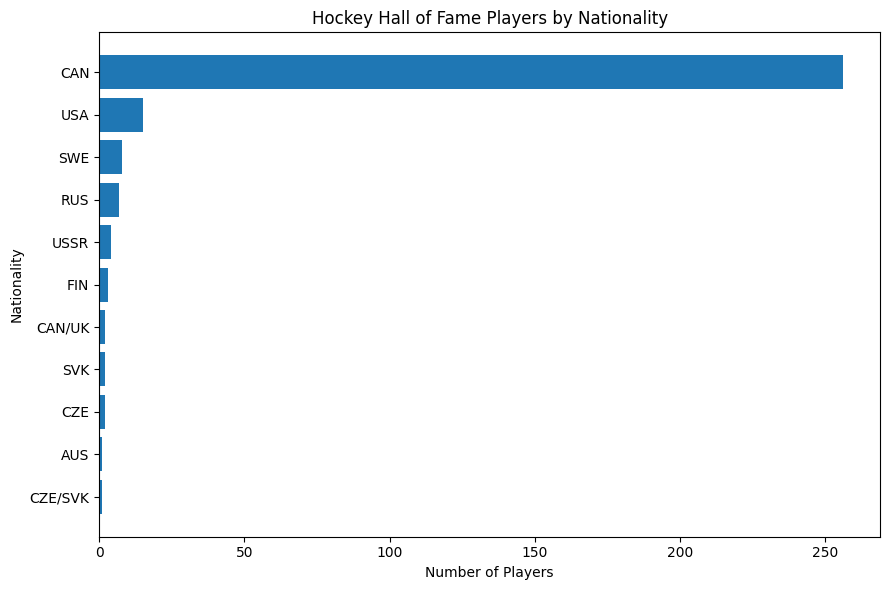

In [42]:
nationality_counts = nationality_counts.sort_values(
    'player_count', ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    nationality_counts['nationality'],
    nationality_counts['player_count']
)

plt.xlabel('Number of Players')
plt.ylabel('Nationality')
plt.title('Hockey Hall of Fame Players by Nationality')

plt.tight_layout()
plt.show()